# Phase 2 LNER — Full Fine-Tuning for Macro-F1

This notebook fine-tunes **all parameters** of the custom Phase 1 decoder plus a new token-classification head. It does **not** use LoRA, adapters, quantization, or a frozen decoder.

### Inputs required in Kaggle
- `custom_bpe_scratch.json` — Phase 1 tokenizer
- `pytorch_model.bin` — Phase 1 pretrained model checkpoint

The Phase 2 dataset (fold 1 training, fold 2 validation, fold 3 test, and `labels.txt`) is downloaded from the Hugging Face dataset repository configured below.

### Workflow
1. Locate and load Phase 1 assets.
2. Define and load the matching custom model architecture.
3. Download and audit Phase 2 data.
4. Align character spans to BPE tokens and build document windows.
5. Fully fine-tune with differential learning rates, class-weighted loss, gradient accumulation, and early stopping.
6. Select by **strict entity-level macro-F1**, restore the best checkpoint, and export Fold 3 predictions.

This v2 debugging and training version supports span annotations stored as either [start, end, label] lists or dictionaries. It stops before training if no gold entities are parsed, audits text/gold document-ID overlap, and reports character-span/BPE boundary coverage. The notebook syntax is checked, but live Hugging Face access and actual training still need to be verified in Kaggle.


This version fixes the previous run's `O`-tag weight bug and applies BIO-constrained Viterbi decoding to reduce invalid fragmented spans.


In [13]:
# ============================================================
# 1. Setup and input assets
# ============================================================
import os
import json
import random
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

# Phase 1 model configuration — must match the checkpoint architecture.
VOCAB_SIZE = 32000
N_EMBD = 512
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048

# Change these only if your Kaggle input files use different names.
BPE_FILENAME = "custom_bpe_scratch.json"
MODEL_FILENAME = "pytorch_model.bin"

def find_input_file(filename):
    """Find an exact filename anywhere under /kaggle/input."""
    roots = [Path("/kaggle/input"), Path.cwd()]
    for root in roots:
        if not root.exists():
            continue
        direct = root / filename
        if direct.is_file():
            return str(direct)
        try:
            for candidate in root.rglob(filename):
                if candidate.is_file():
                    return str(candidate)
        except (PermissionError, OSError):
            pass
    raise FileNotFoundError(
        f"Could not find {filename}. Attach it as a Kaggle input, "
        "or update BPE_FILENAME / MODEL_FILENAME in this cell."
    )

BPE_PATH = find_input_file(BPE_FILENAME)
MODEL_PATH = find_input_file(MODEL_FILENAME)
print("BPE tokenizer:", BPE_PATH)
print("Pretrained model:", MODEL_PATH)

# HF_TOKEN is optional for a public dataset. If the repository is private,
# add a Kaggle secret named HF containing a Hugging Face access token.
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"


Device: cuda
CUDA available: True
BPE tokenizer: /kaggle/input/datasets/baihuwang07/phase1/custom_bpe_scratch.json
Pretrained model: /kaggle/input/datasets/baihuwang07/phase1/pytorch_model.bin


## 2. Load the custom BPE tokenizer


In [14]:
# ============================================================
# 2. Load the custom byte-level BPE tokenizer
# ============================================================
class CustomByteLevelBPE:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {} 
        
        # Base vocabulary of all 256 individual bytes
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        
        # Reserved Special Tokens
        self.pad_id = 0  

    def train(self, texts, target_vocab_size):
        print("Aggregating byte sequence frequencies...")
        word_freqs = Counter()
        
        # 1. Chunk texts to prevent massive contiguous memory blocks
        for text in texts:
            # Split into words and whitespace blocks to keep sequence lengths small
            chunks = re.findall(r'\S+|\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode("utf-8")] += 1
                
        # 2. Drop singletons to massively save RAM
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f"Unique byte sequences to process: {len(word_freqs):,}")

        # Initialize splits: word -> list of byte integers
        splits = {word: list(word) for word in word_freqs}
        
        # 3. Build fast inverted index
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        num_merges = target_vocab_size - 256
        print(f"Starting {num_merges} merges...")
        
        for i in range(num_merges):
            if not pair_counts:
                break
                
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            
            # Record the merge
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            
            # 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
            words_to_update = list(pair_to_words.get(best_pair, []))
            
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                
                # Remove old pairs associated with this word from global tracking
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)

                # Execute the merge on this word's internal list
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # Add newly formed pairs back to global tracking
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
                    
            self.next_id += 1
            
            if (i + 1) % 1000 == 0:
                print(f"Merge {i + 1}/{num_merges} completed.")
                
        print("BPE Training complete!")

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[(ids[i], ids[i+1])] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        # Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents
        chunks = re.findall(r'\S+|\s+', text)
        final_ids = []
        
        for chunk in chunks:
            ids = list(chunk.encode("utf-8"))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break 
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
            
        return final_ids

    def decode(self, ids):
        b_text = b"".join(self.vocab[idx] for idx in ids if idx != self.pad_id)
        return b_text.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{p[0]},{p[1]}": v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {
            "vocab_size": self.vocab_size,
            "next_id": self.next_id,
            "merges": serializable_merges,
            "vocab": serializable_vocab
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
            
        self.vocab_size = data["vocab_size"]
        self.next_id = data["next_id"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}
        self.vocab = {int(k): bytes(v) for k, v in data["vocab"].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(BPE_PATH)
print(f"Loaded BPE vocabulary: {tokenizer.get_vocab_size():,} tokens")


Loaded BPE vocabulary: 32,000 tokens


## 3. Define the Phase 1 model architecture


In [15]:
# ============================================================
# 3. Define the Phase 1 model architecture
# ============================================================
import math
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Apply padding mask for batched inference
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
            
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        
        # QK-Norm layers for stabilization
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        
        # Apply QK-Norm directly after linear projections
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
        q, k = apply_rotary_emb(q, k, freqs_cis)
        
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1),
            attention_mask=attention_mask
        )
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        # Restored separate norm layers for sequential architecture
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        
        # Standard Sequential FFN with SiLU (Swish) instead of GELU
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4, bias=False), 
            nn.SiLU(), 
            nn.Linear(dim * 4, dim, bias=False)
        )
        
    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        # Sequential Residual Architecture
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        
        out = h + self.ffn(self.norm2(h))
        
        return out, new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        
        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        
        h = self.tok_embeddings(tokens)
        new_caches = []
        
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
            
        return self.output(self.norm(h)), new_caches



## 4. Load the Phase 1 checkpoint


In [16]:
# ============================================================
# 4. Load pretrained model weights
# ============================================================
model = CustomLegalModel(
    VOCAB_SIZE,
    N_EMBD,
    N_LAYER,
    N_HEAD,
    N_KV_HEAD,
    MODEL_CONTEXT_LENGTH,
).to(DEVICE)

checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
# Accept either a plain state_dict or common checkpoint wrappers.
if isinstance(checkpoint, dict):
    for key in ("model_state_dict", "state_dict", "model"):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            checkpoint = checkpoint[key]
            break

# Remove a DataParallel prefix if the weights were saved from multiple GPUs.
state_dict = {
    key.removeprefix("module."): value
    for key, value in checkpoint.items()
    if isinstance(value, torch.Tensor)
}
missing, unexpected = model.load_state_dict(state_dict, strict=False)
if missing or unexpected:
    raise RuntimeError(
        "Checkpoint does not exactly match the Phase 1 architecture.\n"
        f"Missing keys (first 10): {missing[:10]}\n"
        f"Unexpected keys (first 10): {unexpected[:10]}"
    )

model.eval()
print(f"Loaded pretrained decoder ({sum(p.numel() for p in model.parameters()):,} parameters).")


Loaded pretrained decoder (59,665,152 parameters).


## 5. Download Phase 2 data and fine-tune the full model

This section contains data parsing, span alignment, document-level evaluation, training, and export.


Phase 2 dataset files downloaded:
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold1-text.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold1-gold.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold2-text.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold2-gold.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/labels.txt
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Test/fold3-text.json
Fold 1

Tokenising Fold 1 train:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 1 train: 681 windows; skipped empty docs: 0


Tokenising Fold 2 validation:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 2 validation: 695 windows; skipped empty docs: 0
O-tag weight: 1.0
Class-weight range: 0.5 2.3002355098724365
BIO-tag weights:
  O                  1.000
  B-APP              1.295
  I-APP              0.747
  B-RESP             1.367
  I-RESP             0.830
  B-A.COUNSEL        2.300
  I-A.COUNSEL        1.300
  B-R.COUNSEL        2.045
  I-R.COUNSEL        1.231
  B-JUDGE            1.777
  I-JUDGE            0.844
  B-WIT              2.273
  I-WIT              1.575
  B-AUTH             0.815
  I-AUTH             0.617
  B-COURT            0.845
  I-COURT            0.523
  B-STAT             0.844
  I-STAT             0.500
  B-PREC             0.727
  I-PREC             0.500
  B-DATE             0.646
  I-DATE             0.500
  B-CASENO           0.923
  I-CASENO           0.500
Full decoder parameters: 59,665,152
Trainable parameters including NER head: 59,677,977
Full fine-tuning enabled: True


Full fine-tuning epoch 1/12:   0%|          | 0/681 [00:00<?, ?it/s]

... (31 outputs left out)

{
  "epoch": 11,
  "train_loss": 0.11001131108776692,
  "val_token_loss": 0.1583015120898893,
  "precision": 0.20695592286501377,
  "recall": 0.1406505967704189,
  "micro_f1": 0.16747944823742514,
  "macro_f1": 0.07786274934384776,
  "tp": 601,
  "fp": 2303,
  "fn": 3672,
  "per_label": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 5,
      "fn": 200
    },
    "RESP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 35,
      "fn": 190
    },
    "A.COUNSEL": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 1,
      "fn": 125
    },
    "R.COUNSEL": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 0,
      "fn": 97
    },
    "JUDGE": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 7,
      "fn": 122
    },
    "WIT": {
      "precision": 0.0,
      "recall": 0.

Full fine-tuning epoch 12/12:   0%|          | 0/681 [00:00<?, ?it/s]

Predicting fold2 epoch 12:   0%|          | 0/35 [00:00<?, ?it/s]

{
  "epoch": 12,
  "train_loss": 0.10403563348110081,
  "val_token_loss": 0.15580347436128644,
  "precision": 0.21452894438138478,
  "recall": 0.13269365785162648,
  "micro_f1": 0.16396761133603238,
  "macro_f1": 0.07762869596103598,
  "tp": 567,
  "fp": 2076,
  "fn": 3706,
  "per_label": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 28,
      "fn": 200
    },
    "RESP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 22,
      "fn": 190
    },
    "A.COUNSEL": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 1,
      "fn": 125
    },
    "R.COUNSEL": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 3,
      "fn": 97
    },
    "JUDGE": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 31,
      "fn": 122
    },
    "WIT": {
      "precision": 0.0,
      "recall"

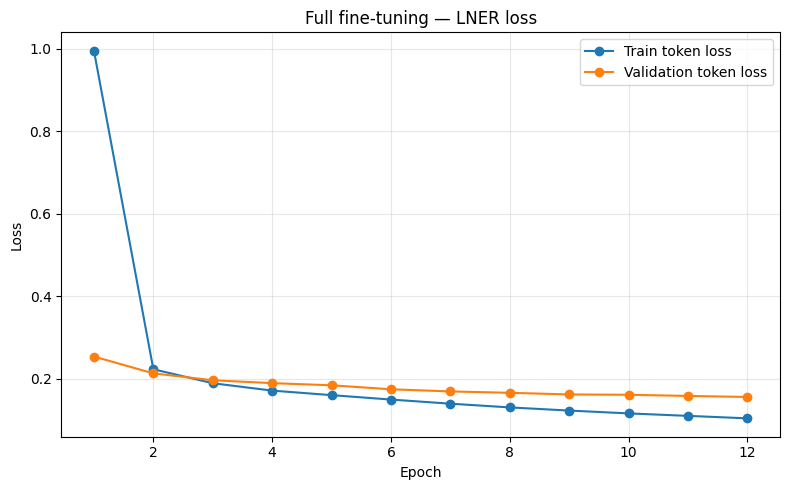

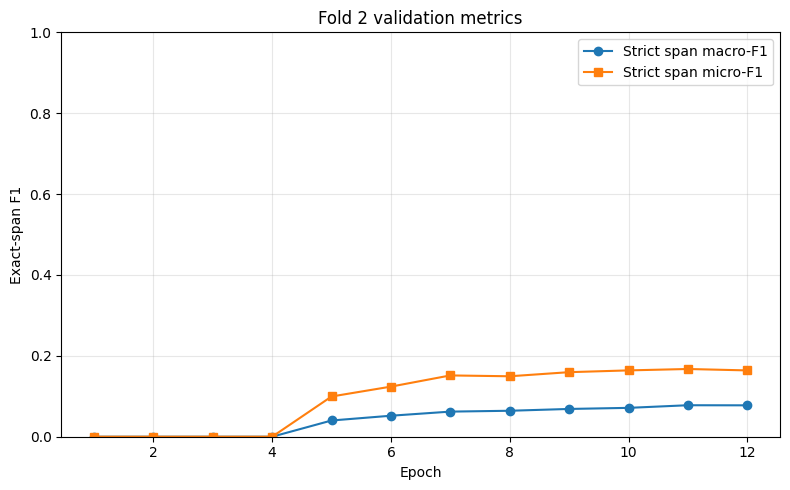

Predicting fold 3:   0%|          | 0/35 [00:00<?, ?it/s]

Phase 2 complete.
Best checkpoint: /kaggle/working/phase2_lner_full_finetuning/best_lner_full_finetuned.pt
Prediction JSON: /kaggle/working/phase2_lner_full_finetuning/prediction.json
Submission ZIP: /kaggle/working/phase2_lner_full_finetuning/submission.zip
Loss plot: /kaggle/working/phase2_lner_full_finetuning/lner_loss_curve.png
Strict-F1 plot: /kaggle/working/phase2_lner_full_finetuning/strict_entity_f1_curve.png
Sample prediction: ('1128835', [[887, 896, 'DATE'], [917, 927, 'COURT'], [951, 956, 'COURT'], [957, 988, 'CASENO'], [1529, 1545, 'STAT'], [1598, 1616, 'DATE'], [1783, 1792, 'DATE'], [2470, 2475, 'DATE'], [2701, 2714, 'DATE'], [2755, 2763, 'DATE'], [3111, 3118, 'DATE'], [3860, 3870, 'DATE'], [4516, 4528, 'STAT'], [4712, 4716, 'DATE'], [4725, 4738, 'CASENO'], [4750, 4760, 'COURT'], [4901, 4911, 'COURT'], [5196, 5202, 'CASENO'], [5494, 5506, 'DATE'], [6323, 6327, 'DATE'], [6443, 6455, 'DATE'], [6456, 6460, 'DATE'], [7471, 7481, 'COURT'], [7498, 7502, 'RESP'], [7511, 7528, 'CA

In [17]:
# Phase 2 L-NER experiment: full decoder fine-tuning + custom token-classification head
# This notebook loads the Phase 1 BPE tokenizer and pretrained model from Kaggle input.
# Phase 2 fold data and labels are downloaded from the Hugging Face dataset repository.

import json
import math
import numpy as np
import os
import re
import zipfile
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# -----------------------------
# Experiment settings
# -----------------------------
LNER_MAX_LEN = 768              # reduce to 512 if GPU memory is tight
LNER_WINDOW_STRIDE = 576        # overlap windows to reduce context-edge errors
LNER_BATCH_SIZE = 1             # safe starting point for full fine-tuning
LNER_GRAD_ACCUM_STEPS = 8       # effective batch size 8 windows
LNER_EPOCHS = 12                # early stopping controls overfitting
LNER_BACKBONE_LR = 1e-5         # conservative LR for pretrained decoder
LNER_HEAD_LR = 5e-5              # new classifier head learns faster
LNER_WEIGHT_DECAY = 0.01
LNER_PATIENCE = 4
LNER_CLASS_WEIGHT_POWER = 0.5   # inverse-frequency weighting softened to avoid rare-class overprediction
LNER_LABEL_SMOOTHING = 0.0
LNER_SEED = 42
LNER_NUM_WORKERS = 0

random_seed = LNER_SEED
import random
random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Download Phase 2 dataset from Hugging Face (no Phase 2 dataset files needed in Kaggle input)
# -----------------------------
from huggingface_hub import hf_hub_download

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_DATASET_SUBDIR = "Phase_2_LNER"

def download_phase2_file(filename, split_folder):
    repo_filename = f"{HF_DATASET_SUBDIR}/{split_folder}/{filename}"
    print(f"Downloading {repo_filename} from {HF_DATASET_REPO} ...")
    return hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=repo_filename,
        repo_type="dataset",
        token=HF_TOKEN or None,
    )

FOLD1_TEXT_PATH = download_phase2_file("fold1-text.json", "Train")
FOLD1_GOLD_PATH = download_phase2_file("fold1-gold.json", "Train")
FOLD2_TEXT_PATH = download_phase2_file("fold2-text.json", "Train")
FOLD2_GOLD_PATH = download_phase2_file("fold2-gold.json", "Train")
LABELS_PATH = download_phase2_file("labels.txt", "Train")
FOLD3_TEXT_PATH = download_phase2_file("fold3-text.json", "Test")

print("Phase 2 dataset files downloaded:")
for _path in (FOLD1_TEXT_PATH, FOLD1_GOLD_PATH, FOLD2_TEXT_PATH,
              FOLD2_GOLD_PATH, LABELS_PATH, FOLD3_TEXT_PATH):
    print("  ", _path)

# -----------------------------
# Read Phase 2 JSON formats
# -----------------------------
def read_json_or_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = f.read()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        rows = []
        for line_no, line in enumerate(raw.splitlines(), 1):
            line = line.strip().rstrip(",")
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_no}") from exc
        return rows


def _first_present(record, keys, default=None):
    for key in keys:
        if key in record:
            return record[key]
    return default


def normalise_documents(raw):
    """Return {str(document_id): document_text}; supports the stated ID -> text layout."""
    if isinstance(raw, dict):
        for container_key in ("documents", "data", "docs", "items"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_documents(raw[container_key])
        docs = {}
        for key, value in raw.items():
            if isinstance(value, str):
                docs[str(key)] = value
            elif isinstance(value, dict):
                text = _first_present(value, ("text", "document", "content", "document_text"))
                doc_id = _first_present(value, ("id", "doc_id", "document_id", "docid"), key)
                if isinstance(text, str):
                    docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document text. Expected a document-ID-to-text JSON object or records with id/text fields.")
        return docs
    if isinstance(raw, list):
        docs = {}
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("id", "doc_id", "document_id", "docid", "documentId"))
            text = _first_present(row, ("text", "document", "content", "document_text"))
            if doc_id is not None and isinstance(text, str):
                docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document ID/text records in the JSON list.")
        return docs
    raise ValueError(f"Unsupported document JSON root type: {type(raw).__name__}")


def normalise_entity(entity):
    """
    Accept both common annotation encodings:
      {"start": 1, "end": 5, "label": "COURT", "text": "..."}
      [1, 5, "COURT"] or [1, 5, "COURT", "..."]
    Offsets use end-exclusive character indexing.
    """
    if isinstance(entity, (list, tuple)):
        if len(entity) < 3:
            return None
        start, end, label = entity[:3]
        text = entity[3] if len(entity) > 3 else ""
    elif isinstance(entity, dict):
        start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
        end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
        label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
        text = _first_present(entity, ("text", "entity_text", "surface"), "")
    else:
        return None

    if start is None or end is None or label is None:
        return None
    try:
        start, end = int(start), int(end)
    except (TypeError, ValueError):
        return None
    if end <= start:
        return None
    return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}


def normalise_gold(raw):
    """Return {str(document_id): [normalized entity dicts]} for document-keyed or record-list JSON."""
    if isinstance(raw, dict):
        for container_key in ("annotations", "entities_by_document", "data", "documents", "records"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_gold(raw[container_key])
        out = {}
        for doc_id, value in raw.items():
            if isinstance(value, list):
                ents = [normalise_entity(e) for e in value]
            elif isinstance(value, dict):
                embedded = _first_present(value, ("entities", "annotations", "spans"))
                if isinstance(embedded, list):
                    ents = [normalise_entity(e) for e in embedded]
                elif _first_present(value, ("start", "start_offset", "start_char")) is not None:
                    ent = normalise_entity(value)
                    record_id = _first_present(value, ("doc_id", "document_id", "docid", "id"), doc_id)
                    out.setdefault(str(record_id), [])
                    if ent is not None:
                        out[str(record_id)].append(ent)
                    continue
                else:
                    continue
            else:
                continue
            out[str(doc_id)] = [e for e in ents if e is not None]
        if not out:
            raise ValueError("Could not parse gold annotations. Expected a document-ID-to-entity-list mapping.")
        return out
    if isinstance(raw, list):
        out = defaultdict(list)
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("doc_id", "document_id", "docid", "documentId", "id"))
            embedded = _first_present(row, ("entities", "annotations", "spans"))
            if doc_id is not None and isinstance(embedded, list):
                out[str(doc_id)].extend(e for e in (normalise_entity(x) for x in embedded) if e is not None)
                continue
            ent = normalise_entity(row)
            if doc_id is not None and ent is not None:
                out[str(doc_id)].append(ent)
        if not out:
            raise ValueError("Could not parse gold records from JSON list.")
        return dict(out)
    raise ValueError(f"Unsupported gold JSON root type: {type(raw).__name__}")


fold1_docs = normalise_documents(read_json_or_jsonl(FOLD1_TEXT_PATH))
fold1_gold = normalise_gold(read_json_or_jsonl(FOLD1_GOLD_PATH))
fold2_docs = normalise_documents(read_json_or_jsonl(FOLD2_TEXT_PATH))
fold2_gold = normalise_gold(read_json_or_jsonl(FOLD2_GOLD_PATH))
test_docs = normalise_documents(read_json_or_jsonl(FOLD3_TEXT_PATH))
with open(LABELS_PATH, "r", encoding="utf-8") as f:
    ENTITY_LABELS = [line.strip() for line in f if line.strip()]
# Handle a leading UTF-8 BOM and duplicate blank/duplicate label lines defensively.
ENTITY_LABELS = list(dict.fromkeys(label.lstrip("\ufeff").strip() for label in ENTITY_LABELS if label.strip()))
if not ENTITY_LABELS:
    raise ValueError("labels.txt is empty; cannot construct the entity classifier.")

print(f"Fold 1: {len(fold1_docs)} documents; {sum(len(fold1_gold.get(k, [])) for k in fold1_docs)} entities")
print(f"Fold 2: {len(fold2_docs)} documents; {sum(len(fold2_gold.get(k, [])) for k in fold2_docs)} entities")
print(f"Test:   {len(test_docs)} documents")

print("Entity labels:", ENTITY_LABELS)

def audit_phase2_data(documents, gold_by_doc, split_name):
    doc_ids = set(map(str, documents.keys()))
    gold_ids = set(map(str, gold_by_doc.keys()))
    matched_ids = doc_ids & gold_ids
    total_entities = sum(len(gold_by_doc.get(doc_id, [])) for doc_id in doc_ids)
    print(
        f"[{split_name} audit] docs={len(doc_ids):,}; gold-doc IDs={len(gold_ids):,}; "
        f"ID overlap={len(matched_ids):,}; gold entities={total_entities:,}"
    )
    if not documents:
        raise ValueError(f"{split_name}: no documents were loaded.")
    if not gold_by_doc:
        raise ValueError(
            f"{split_name}: no gold annotation records were parsed. "
            "Inspect the raw fold*-gold.json schema."
        )
    if total_entities == 0:
        # Show a raw annotation example to make schema mismatches obvious.
        sample_id = next(iter(gold_by_doc), None)
        sample_value = gold_by_doc.get(sample_id) if sample_id is not None else None
        raise ValueError(
            f"{split_name}: zero entities were parsed. This would inevitably produce 0 F1. "
            f"Example parsed gold for ID {sample_id!r}: {sample_value!r}. "
            "Expected each span to be [start, end, label] or a dict with start/end/label fields."
        )
    if not matched_ids:
        raise ValueError(
            f"{split_name}: document IDs in text and gold do not overlap. "
            f"Example text IDs: {list(doc_ids)[:3]}; gold IDs: {list(gold_ids)[:3]}"
        )
    bad_labels = sorted({
        str(ent.get("label"))
        for doc_id in matched_ids
        for ent in gold_by_doc.get(doc_id, [])
        if str(ent.get("label")) not in ENTITY_LABELS
    })
    if bad_labels:
        raise ValueError(
            f"{split_name}: annotation labels are not present in labels.txt: {bad_labels}. "
            f"Official labels: {ENTITY_LABELS}"
        )
    print(f"[{split_name} audit] sample gold: {next(iter(gold_by_doc.items()))[1][:3]}")

audit_phase2_data(fold1_docs, fold1_gold, "Fold 1")
audit_phase2_data(fold2_docs, fold2_gold, "Fold 2")

# -----------------------------
# Custom byte-level BPE encoder with character offsets
# -----------------------------
def encode_with_character_offsets(tokenizer, text, verify_parity=False):
    """Mirror CustomByteLevelBPE.encode() exactly while tracking Unicode character spans.

    The Phase 1 tokenizer is byte-level. Each UTF-8 byte initially maps to the Unicode
    character that generated it; merged byte tokens combine those spans. End offsets are
    exclusive, matching the Phase 2 character-span annotation convention.
    """
    all_ids, all_offsets = [], []
    if not text:
        return all_ids, all_offsets

    for match in re.finditer(r"\S+|\s+", text):
        chunk = match.group(0)
        ids = list(chunk.encode("utf-8"))
        spans = []
        absolute_char = match.start()
        for local_char, ch in enumerate(chunk):
            char_span = (absolute_char + local_char, absolute_char + local_char + 1)
            spans.extend([char_span] * len(ch.encode("utf-8")))

        # Same greedy merge priority as CustomByteLevelBPE.encode(): lowest merge ID first.
        while len(ids) >= 2:
            eligible = []
            for i in range(len(ids) - 1):
                pair = (ids[i], ids[i + 1])
                if pair in tokenizer.merges:
                    eligible.append((tokenizer.merges[pair], i, pair))
            if not eligible:
                break
            merge_id, _, pair = min(eligible, key=lambda x: (x[0], x[1]))

            new_ids, new_spans = [], []
            i = 0
            while i < len(ids):
                if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
                    new_ids.append(merge_id)
                    new_spans.append((spans[i][0], max(spans[i][1], spans[i + 1][1])))
                    i += 2
                else:
                    new_ids.append(ids[i])
                    new_spans.append(spans[i])
                    i += 1
            ids, spans = new_ids, new_spans

        all_ids.extend(ids)
        all_offsets.extend(spans)

    # Optional parity check against the notebook's original tokenizer implementation.
    # Run this on a representative document once; repeating it for every document doubles
    # the tokenizer work and can be costly for a custom BPE implementation.
    if verify_parity:
        original_ids = tokenizer.encode(text)
        if all_ids != original_ids:
            raise RuntimeError(
                "Offset-aware BPE differs from tokenizer.encode() for this text. "
                "Check the custom tokenizer's merge implementation before training."
            )
    return all_ids, all_offsets


# One-time parity check: avoid running the original tokenizer a second time for every document.
_parity_sample = next(iter(fold1_docs.values()), "")
if _parity_sample:
    _parity_ids, _parity_offsets = encode_with_character_offsets(tokenizer, _parity_sample, verify_parity=True)
    assert len(_parity_ids) == len(_parity_offsets)
    print("Offset-aware BPE parity check passed on one fold-1 document.")


# -----------------------------
# Alignment coverage audit: catch tokenizer/character-offset issues before training
# -----------------------------
def audit_entity_alignment(documents, gold_by_doc, max_documents=200):
    total = 0
    exactly_representable = 0
    per_label = defaultdict(lambda: [0, 0])  # [representable, total]
    for doc_id, text in list(documents.items())[:max_documents]:
        entities = gold_by_doc.get(str(doc_id), [])
        if not entities:
            continue
        _, offsets = encode_with_character_offsets(tokenizer, text)
        token_starts = {a for a, _ in offsets}
        token_ends = {b for _, b in offsets}
        for entity in entities:
            start, end, label = entity["start"], entity["end"], entity["label"]
            total += 1
            per_label[label][1] += 1
            # This tokenizer covers the source string in order, so exact start/end token
            # boundaries are the key representability test.
            exact = start in token_starts and end in token_ends and end > start
            if exact:
                exactly_representable += 1
                per_label[label][0] += 1
    coverage = exactly_representable / max(1, total)
    print(f"Gold-span exact BPE boundary coverage in audit sample: {exactly_representable}/{total} = {coverage:.1%}")
    for label, (ok, n) in sorted(per_label.items()):
        print(f"  {label:16s} {ok:5d}/{n:<5d} ({ok/max(1,n):.1%})")
    if total and coverage < 0.50:
        print(
            "WARNING: Many gold spans do not align to exact BPE token boundaries. "
            "A BIO token head may be unable to reproduce their character spans exactly; "
            "consider a span-classification head or a tokenizer-aware boundary strategy."
        )

# -----------------------------
# Character spans -> BIO token tags
# -----------------------------
TAG_NAMES = ["O"]
for _label in ENTITY_LABELS:
    TAG_NAMES.extend((f"B-{_label}", f"I-{_label}"))
TAG_TO_ID = {tag: idx for idx, tag in enumerate(TAG_NAMES)}
ID_TO_TAG = {idx: tag for tag, idx in TAG_TO_ID.items()}
IGNORE_INDEX = -100

audit_entity_alignment(fold1_docs, fold1_gold)
audit_entity_alignment(fold2_docs, fold2_gold)


def normalise_entity_spans(entities, text_length):
    result = []
    for entity in entities:
        start, end, label = int(entity["start"]), int(entity["end"]), str(entity["label"])
        if label not in ENTITY_LABELS:
            raise ValueError(f"Unknown entity label {label!r}; labels.txt contains {ENTITY_LABELS}")
        if start < 0 or end > text_length or end <= start:
            raise ValueError(f"Invalid entity offsets {(start, end)} for text length {text_length}")
        result.append((start, end, label))
    result.sort(key=lambda item: (item[0], item[1]))
    # The BIO token head assumes flat, non-overlapping named entities.
    for left, right in zip(result, result[1:]):
        if right[0] < left[1]:
            raise ValueError(f"Overlapping/nested annotations not supported by flat BIO head: {left} and {right}")
    return result


def align_offsets_to_bio(offsets, entities, text_length):
    """Align token spans to entity spans. Partial boundary-crossing tokens are ignored in loss."""
    entity_spans = normalise_entity_spans(entities, text_length)
    tag_strings = ["O"] * len(offsets)
    ignore = [False] * len(offsets)
    contained_by_entity = [[] for _ in entity_spans]
    entity_cursor = 0

    # Both token offsets and entity spans are ordered. Use a sweep rather than an O(tokens*entities) scan.
    for token_i, (tok_start, tok_end) in enumerate(offsets):
        if tok_end <= tok_start:
            ignore[token_i] = True
            continue
        while entity_cursor < len(entity_spans) and entity_spans[entity_cursor][1] <= tok_start:
            entity_cursor += 1
        overlaps = []
        j = entity_cursor
        while j < len(entity_spans) and entity_spans[j][0] < tok_end:
            ent_start, ent_end, _ = entity_spans[j]
            if max(tok_start, ent_start) < min(tok_end, ent_end):
                overlaps.append(j)
            j += 1
        if len(overlaps) > 1:
            ignore[token_i] = True
        elif overlaps:
            ent_index = overlaps[0]
            ent_start, ent_end, _ = entity_spans[ent_index]
            if tok_start >= ent_start and tok_end <= ent_end:
                contained_by_entity[ent_index].append(token_i)
            else:
                ignore[token_i] = True

    # First wholly contained token gets B-X; remaining contained tokens get I-X.
    for entity_index, token_indices in enumerate(contained_by_entity):
        if not token_indices:
            # An annotation boundary falls inside a merged BPE token; this token sequence cannot
            # represent that exact boundary, so no fabricated boundary label is assigned.
            continue
        label = entity_spans[entity_index][2]
        for j, token_i in enumerate(token_indices):
            tag_strings[token_i] = f"B-{label}" if j == 0 else f"I-{label}"

    return [IGNORE_INDEX if ignore[i] else TAG_TO_ID[tag_strings[i]] for i in range(len(offsets))]


def make_window_starts(n_tokens, max_len=LNER_MAX_LEN, stride=LNER_WINDOW_STRIDE):
    if n_tokens <= 0:
        return []
    if n_tokens <= max_len:
        return [0]
    stride = min(max(1, stride), max_len)
    return list(range(0, n_tokens, stride))


def fix_bio_window_edges(label_ids):
    """Reset orphan I-tags at a chunk boundary to B-tags for window training."""
    result = list(label_ids)
    active_type = None
    for i, tag_id in enumerate(result):
        if tag_id == IGNORE_INDEX:
            active_type = None
            continue
        tag = ID_TO_TAG[tag_id]
        if tag == "O":
            active_type = None
        elif tag.startswith("B-"):
            active_type = tag[2:]
        elif tag.startswith("I-"):
            ent_type = tag[2:]
            if active_type != ent_type:
                result[i] = TAG_TO_ID[f"B-{ent_type}"]
            active_type = ent_type
    return result


def build_training_windows(documents, gold_by_doc, split_name):
    windows = []
    skipped_empty = 0
    for doc_id, text in tqdm(documents.items(), desc=f"Tokenising {split_name}"):
        token_ids, offsets = encode_with_character_offsets(tokenizer, text)
        if not token_ids:
            skipped_empty += 1
            continue
        entities = gold_by_doc.get(str(doc_id), [])
        labels = align_offsets_to_bio(offsets, entities, len(text))
        for start in make_window_starts(len(token_ids)):
            end = min(start + LNER_MAX_LEN, len(token_ids))
            window_ids = token_ids[start:end]
            window_labels = fix_bio_window_edges(labels[start:end])
            windows.append({
                "doc_id": str(doc_id),
                "input_ids": window_ids,
                "labels": window_labels,
            })
            if end == len(token_ids):
                break
    print(f"{split_name}: {len(windows)} windows; skipped empty docs: {skipped_empty}")
    return windows


train_windows = build_training_windows(fold1_docs, fold1_gold, "Fold 1 train")
val_windows_for_loss = build_training_windows(fold2_docs, fold2_gold, "Fold 2 validation")
if not train_windows:
    raise RuntimeError("No training windows were produced; verify paths and document JSON schema.")

# -----------------------------
# Custom token classification head + manual masked cross entropy
# -----------------------------
class CustomTokenClassificationHead(nn.Module):
    def __init__(self, hidden_size, num_tags, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def forward(self, hidden_states):
        return self.classifier(self.dropout(hidden_states))


def manual_masked_token_cross_entropy(
    logits,
    target_ids,
    class_weights=None,
    ignore_index=IGNORE_INDEX,
    label_smoothing=0.0,
):
    """Masked cross entropy with optional soft class weights and label smoothing."""
    flat_logits = logits.reshape(-1, logits.shape[-1]).float()
    flat_targets = target_ids.reshape(-1)
    valid = flat_targets.ne(ignore_index)
    if not bool(valid.any()):
        return logits.float().sum() * 0.0

    selected_logits = flat_logits[valid]
    selected_targets = flat_targets[valid]
    log_probs = F.log_softmax(selected_logits, dim=-1)

    if label_smoothing > 0:
        n_classes = selected_logits.shape[-1]
        nll = -log_probs.gather(1, selected_targets.unsqueeze(1)).squeeze(1)
        smooth = -log_probs.mean(dim=-1)
        per_token_loss = (1.0 - label_smoothing) * nll + label_smoothing * smooth
    else:
        per_token_loss = -log_probs.gather(1, selected_targets.unsqueeze(1)).squeeze(1)

    if class_weights is None:
        return per_token_loss.mean()

    weights = class_weights.to(selected_targets.device)[selected_targets]
    return (per_token_loss * weights).sum() / weights.sum().clamp_min(1e-8)


# Compute weights only from training labels (never from validation/test labels).
_tag_counts = torch.zeros(len(TAG_NAMES), dtype=torch.float64)
for _window in train_windows:
    for _tag in _window["labels"]:
        if _tag != IGNORE_INDEX:
            _tag_counts[_tag] += 1
_valid_counts = _tag_counts.clamp_min(1.0)
_inverse = (_valid_counts.sum() / (_valid_counts * len(TAG_NAMES))).pow(LNER_CLASS_WEIGHT_POWER)
_inverse = _inverse / _inverse.mean()

# IMPORTANT FIX:
# `min(O_weight, 1.0)` does NOT set O's weight to 1. It leaves a tiny value
# (about 0.03 in the prior run), causing the model to ignore non-entity tokens
# and emit enormous numbers of false-positive entities.
_inverse[0] = 1.0

# Clip the remaining BIO-tag weights to prevent rare labels from dominating.
_inverse[1:] = _inverse[1:].clamp(min=0.5, max=3.0)
CLASS_WEIGHTS = _inverse.float().to(DEVICE)
print("O-tag weight:", float(CLASS_WEIGHTS[0]))
print("Class-weight range:", float(CLASS_WEIGHTS.min()), float(CLASS_WEIGHTS.max()))
print("BIO-tag weights:")
for _i, _tag in enumerate(TAG_NAMES):
    print(f"  {_tag:18s} {float(CLASS_WEIGHTS[_i]):.3f}")


# -----------------------------
# Prepare Phase 1 decoder for FULL fine-tuning
# -----------------------------
if "model" not in globals() or "tokenizer" not in globals():
    raise RuntimeError("Load the Phase 1 model and tokenizer before running this cell.")

phase1_decoder = model.module if isinstance(model, nn.DataParallel) else model
phase1_decoder.to(DEVICE)
for parameter in phase1_decoder.parameters():
    parameter.requires_grad_(True)

hidden_size = phase1_decoder.tok_embeddings.embedding_dim
ner_head = CustomTokenClassificationHead(hidden_size, len(TAG_NAMES), dropout=0.1).to(DEVICE)

def decoder_hidden_states(decoder, input_ids, attention_mask=None):
    """Run the decoder and return final normalized hidden states for NER."""
    batch_size, seq_len = input_ids.shape
    if seq_len > decoder.freqs_cis.shape[0]:
        raise ValueError(
            f"Sequence length {seq_len} exceeds model context {decoder.freqs_cis.shape[0]}"
        )
    freqs_cis = decoder.freqs_cis[:seq_len].to(input_ids.device)
    freqs_cis = torch.view_as_complex(freqs_cis)
    hidden = decoder.tok_embeddings(input_ids)
    for layer in decoder.layers:
        hidden, _ = layer(
            hidden,
            freqs_cis,
            kv_cache=None,
            attention_mask=attention_mask,
        )
    return decoder.norm(hidden)

decoder_parameter_count = sum(p.numel() for p in phase1_decoder.parameters())
head_parameter_count = sum(p.numel() for p in ner_head.parameters())
trainable_parameters = [
    p for p in phase1_decoder.parameters() if p.requires_grad
] + list(ner_head.parameters())
print(f"Full decoder parameters: {decoder_parameter_count:,}")
print(f"Trainable parameters including NER head: {sum(p.numel() for p in trainable_parameters):,}")
print("Full fine-tuning enabled:", all(p.requires_grad for p in phase1_decoder.parameters()))

# -----------------------------
# Batching
# -----------------------------
PAD_ID = int(getattr(tokenizer, "pad_id", 0))

class LNERWindowDataset(Dataset):
    def __init__(self, windows):
        self.windows = windows
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, index):
        return self.windows[index]


def collate_lner(batch):
    max_len = max(len(row["input_ids"]) for row in batch)
    batch_size = len(batch)
    input_ids = torch.full((batch_size, max_len), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((batch_size, max_len), dtype=torch.long)
    labels = torch.full((batch_size, max_len), IGNORE_INDEX, dtype=torch.long)
    for i, row in enumerate(batch):
        length = len(row["input_ids"])
        input_ids[i, :length] = torch.tensor(row["input_ids"], dtype=torch.long)
        attention_mask[i, :length] = 1
        if "labels" in row:
            labels[i, :length] = torch.tensor(row["labels"], dtype=torch.long)
    return input_ids, attention_mask, labels


train_loader = DataLoader(
    LNERWindowDataset(train_windows), batch_size=LNER_BATCH_SIZE, shuffle=True,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)
val_loss_loader = DataLoader(
    LNERWindowDataset(val_windows_for_loss), batch_size=LNER_BATCH_SIZE, shuffle=False,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)

# -----------------------------
# Prediction utilities: windows -> averaged token logits -> exact character spans
# -----------------------------
@torch.no_grad()
def predict_document_logits(text, decoder, head, batch_window_size=4):
    token_ids, offsets = encode_with_character_offsets(tokenizer, text)
    if not token_ids:
        return token_ids, offsets, torch.empty((0, len(TAG_NAMES)), dtype=torch.float32)
    starts = make_window_starts(len(token_ids))
    accum = torch.zeros((len(token_ids), len(TAG_NAMES)), device=DEVICE, dtype=torch.float32)
    counts = torch.zeros((len(token_ids), 1), device=DEVICE, dtype=torch.float32)
    decoder.eval(); head.eval()
    use_amp = DEVICE.type == "cuda"
    for block in range(0, len(starts), batch_window_size):
        group_starts = starts[block:block + batch_window_size]
        rows = []
        positions = []
        for start in group_starts:
            end = min(start + LNER_MAX_LEN, len(token_ids))
            rows.append({"input_ids": token_ids[start:end]})
            positions.append((start, end))
        input_ids, attention_mask, _ = collate_lner(rows)
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            hidden = decoder_hidden_states(decoder, input_ids, attention_mask)
            logits = head(hidden).float()
        for row_i, (start, end) in enumerate(positions):
            length = end - start
            accum[start:end] += logits[row_i, :length]
            counts[start:end] += 1.0
    averaged = accum / counts.clamp_min(1.0)
    return token_ids, offsets, averaged.cpu()


def bio_tags_to_character_spans(tag_ids, offsets):
    spans = []
    active_start = active_end = None
    active_label = None

    def close_active():
        nonlocal active_start, active_end, active_label
        if active_label is not None and active_start is not None and active_end is not None and active_end > active_start:
            spans.append((int(active_start), int(active_end), str(active_label)))
        active_start = active_end = active_label = None

    for tag_id, (start, end) in zip(tag_ids, offsets):
        if tag_id == IGNORE_INDEX or end <= start:
            close_active()
            continue
        tag = ID_TO_TAG[int(tag_id)]
        if tag == "O":
            close_active()
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B":
            close_active()
            active_start, active_end, active_label = start, end, label
        else:  # I-label; an orphan I is treated as a new entity.
            if active_label == label and active_end is not None and start <= active_end:
                active_end = max(active_end, end)
            else:
                close_active()
                active_start, active_end, active_label = start, end, label
    close_active()
    # Deduplicate repeated character spans produced by multiple bytes of a Unicode character.
    unique = sorted(set(spans), key=lambda item: (item[0], item[1], item[2]))
    return unique


def decode_bio_viterbi(logits):
    """
    Decode the most likely valid BIO sequence in O(sequence_length * tag_count).

    An I-LABEL tag is only allowed after B-LABEL or I-LABEL. O and B-* can
    follow any tag. This prevents orphan I-tags from being turned into many
    accidental short entities during span conversion.
    """
    emissions = logits.detach().float().cpu().numpy()
    if emissions.shape[0] == 0:
        return []

    num_tags = len(TAG_NAMES)
    labels_for_prefix = {}
    for tag_id, tag in ID_TO_TAG.items():
        if tag.startswith(("B-", "I-")):
            prefix, label = tag.split("-", 1)
            labels_for_prefix.setdefault(label, {})[prefix] = tag_id

    # dp[t] stores the best score ending in each tag after token t.
    dp = emissions[0].copy()
    backpointers = []

    # An entity cannot begin with I-*.
    for tag_id, tag in ID_TO_TAG.items():
        if tag.startswith("I-"):
            dp[tag_id] = -1e12

    for t in range(1, emissions.shape[0]):
        best_prev = int(dp.argmax())
        next_scores = np.empty(num_tags, dtype=np.float32)
        back = np.full(num_tags, best_prev, dtype=np.int32)
        best_score = float(dp[best_prev])

        # O and B-* may follow any previous state.
        for current_id, current_tag in ID_TO_TAG.items():
            if current_tag == "O" or current_tag.startswith("B-"):
                next_scores[current_id] = best_score + emissions[t, current_id]
            else:
                label = current_tag[2:]
                ids_for_label = labels_for_prefix[label]
                allowed_prev = [ids_for_label["B"], ids_for_label["I"]]
                previous_scores = dp[allowed_prev]
                local_index = int(previous_scores.argmax())
                chosen_prev = allowed_prev[local_index]
                next_scores[current_id] = dp[chosen_prev] + emissions[t, current_id]
                back[current_id] = chosen_prev

        backpointers.append(back)
        dp = next_scores

    current = int(dp.argmax())
    path = [current]
    for back in reversed(backpointers):
        current = int(back[current])
        path.append(current)
    path.reverse()
    return path


@torch.no_grad()
def predict_document_spans(text, decoder, head):
    ids, offsets, logits = predict_document_logits(text, decoder, head)
    if not ids:
        return []
    tag_ids = decode_bio_viterbi(logits)
    return bio_tags_to_character_spans(tag_ids, offsets)


def strict_entity_metrics(gold_documents, pred_documents, label_names):
    gold = set()
    pred = set()
    for doc_id, entities in gold_documents.items():
        for ent in entities:
            gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
    for doc_id, spans in pred_documents.items():
        for start, end, label in spans:
            pred.add((str(doc_id), int(start), int(end), str(label)))
    tp = len(gold & pred)
    fp = len(pred - gold)
    fn = len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    per_label = {}
    for label in label_names:
        g = {x for x in gold if x[3] == label}
        p = {x for x in pred if x[3] == label}
        ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
        lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
        lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
        lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
        per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
    macro_f1 = sum(values["f1"] for values in per_label.values()) / max(1, len(per_label))
    return {"precision": precision, "recall": recall, "micro_f1": micro_f1, "macro_f1": macro_f1, "tp": tp, "fp": fp, "fn": fn, "per_label": per_label}


@torch.no_grad()
def evaluate_fold(documents, gold_by_doc, decoder, head, split_name="validation"):
    decoder.eval(); head.eval()
    predictions = {}
    for doc_id, text in tqdm(documents.items(), desc=f"Predicting {split_name}"):
        predictions[str(doc_id)] = predict_document_spans(text, decoder, head)
    metrics = strict_entity_metrics(gold_by_doc, predictions, ENTITY_LABELS)
    return metrics, predictions


# -----------------------------
# Full fine-tuning, validation, early stopping, and checkpoint selection
# -----------------------------
backbone_parameters = list(phase1_decoder.parameters())
head_parameters = list(ner_head.parameters())
optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": LNER_BACKBONE_LR},
        {"params": head_parameters, "lr": LNER_HEAD_LR},
    ],
    weight_decay=LNER_WEIGHT_DECAY,
    betas=(0.9, 0.95),
    eps=1e-8,
)
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1, min_lr=1e-7
)

def validate_token_loss():
    phase1_decoder.eval()
    ner_head.eval()
    total_loss = 0.0
    total_tokens = 0
    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loss_loader:
            input_ids = input_ids.to(DEVICE, non_blocking=True)
            attention_mask = attention_mask.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
                logits = ner_head(hidden)
                loss = manual_masked_token_cross_entropy(
                    logits, labels, CLASS_WEIGHTS, label_smoothing=LNER_LABEL_SMOOTHING
                )
            valid_count = int(labels.ne(IGNORE_INDEX).sum())
            if valid_count:
                total_loss += float(loss.detach().cpu()) * valid_count
                total_tokens += valid_count
    return total_loss / max(1, total_tokens)

PHASE2_OUT_DIR = Path("/kaggle/working/phase2_lner_full_finetuning")
PHASE2_OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = PHASE2_OUT_DIR / "best_lner_full_finetuned.pt"
history = []
best_macro_f1 = -1.0
epochs_without_improvement = 0
optimizer_steps = 0

for epoch in range(1, LNER_EPOCHS + 1):
    phase1_decoder.train()
    ner_head.train()
    optimizer.zero_grad(set_to_none=True)
    batch_losses = []
    pbar = tqdm(enumerate(train_loader), total=len(train_loader),
                desc=f"Full fine-tuning epoch {epoch}/{LNER_EPOCHS}")
    for batch_index, (input_ids, attention_mask, labels) in pbar:
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
            logits = ner_head(hidden)
            loss = manual_masked_token_cross_entropy(
                logits, labels, CLASS_WEIGHTS, label_smoothing=LNER_LABEL_SMOOTHING
            )
            scaled_loss = loss / LNER_GRAD_ACCUM_STEPS

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite training loss at epoch {epoch}: {float(loss.detach().cpu())}"
            )
        scaler.scale(scaled_loss).backward()
        batch_losses.append(float(loss.detach().detach().cpu()))
        is_accumulation_boundary = (
            (batch_index + 1) % LNER_GRAD_ACCUM_STEPS == 0
            or (batch_index + 1) == len(train_loader)
        )
        if is_accumulation_boundary:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            optimizer_steps += 1
        pbar.set_postfix(loss=f"{batch_losses[-1]:.4f}", steps=optimizer_steps)

    train_loss = sum(batch_losses) / max(1, len(batch_losses))
    val_loss = validate_token_loss()
    val_metrics, val_predictions = evaluate_fold(
        fold2_docs, fold2_gold, phase1_decoder, ner_head, split_name=f"fold2 epoch {epoch}"
    )
    scheduler.step(val_metrics["macro_f1"])

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_token_loss": val_loss,
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "micro_f1": val_metrics["micro_f1"],
        "macro_f1": val_metrics["macro_f1"],
        "tp": val_metrics["tp"],
        "fp": val_metrics["fp"],
        "fn": val_metrics["fn"],
        "per_label": val_metrics["per_label"],
        "learning_rates": [group["lr"] for group in optimizer.param_groups],
    }
    history.append(row)
    print(json.dumps(row, indent=2))

    if val_metrics["macro_f1"] > best_macro_f1 + 1e-6:
        best_macro_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0
        torch.save(
            {
                "decoder_state_dict": phase1_decoder.state_dict(),
                "ner_head_state_dict": ner_head.state_dict(),
                "entity_labels": ENTITY_LABELS,
                "tag_names": TAG_NAMES,
                "best_macro_f1": best_macro_f1,
                "max_len": LNER_MAX_LEN,
                "window_stride": LNER_WINDOW_STRIDE,
                "tokenizer_vocab_size": tokenizer.get_vocab_size(),
                "history": history,
                "model_config": {
                    "vocab_size": VOCAB_SIZE,
                    "n_embd": N_EMBD,
                    "n_layer": N_LAYER,
                    "n_head": N_HEAD,
                    "n_kv_head": N_KV_HEAD,
                    "context_length": MODEL_CONTEXT_LENGTH,
                },
            },
            BEST_CHECKPOINT_PATH,
        )
        print(f"Saved best full-fine-tuned checkpoint: {BEST_CHECKPOINT_PATH}")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= LNER_PATIENCE:
            print(f"Early stopping after {epoch} epochs; best macro-F1={best_macro_f1:.4f}")
            break

with open(PHASE2_OUT_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

import matplotlib.pyplot as plt
_epochs = [item["epoch"] for item in history]
plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["train_loss"] for item in history], marker="o", label="Train token loss")
plt.plot(_epochs, [item["val_token_loss"] for item in history], marker="o", label="Validation token loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Full fine-tuning — LNER loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
LOSS_PLOT_PATH = PHASE2_OUT_DIR / "lner_loss_curve.png"
plt.savefig(LOSS_PLOT_PATH, dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["macro_f1"] for item in history], marker="o", label="Strict span macro-F1")
plt.plot(_epochs, [item["micro_f1"] for item in history], marker="s", label="Strict span micro-F1")
plt.xlabel("Epoch")
plt.ylabel("Exact-span F1")
plt.title("Fold 2 validation metrics")
plt.ylim(0.0, 1.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
F1_PLOT_PATH = PHASE2_OUT_DIR / "strict_entity_f1_curve.png"
plt.savefig(F1_PLOT_PATH, dpi=160)
plt.show()

# Reload the best checkpoint before Fold 3 inference.
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
phase1_decoder.load_state_dict(checkpoint["decoder_state_dict"])
ner_head.load_state_dict(checkpoint["ner_head_state_dict"])
phase1_decoder.eval()
ner_head.eval()

# -----------------------------
# Final fold-3 prediction + Codabench archive
# -----------------------------
fold3_predictions = {}
for doc_id, text in tqdm(test_docs.items(), desc="Predicting fold 3"):
    spans = predict_document_spans(text, phase1_decoder, ner_head)
    # The official schema scores [start_character, end_character, label]; entity text is optional.
    fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

prediction_path = PHASE2_OUT_DIR / "prediction.json"
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)

submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(prediction_path, arcname="prediction.json")

# Sanity checks: every official test ID appears and the zip entry is at its root.
assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Some test document IDs are missing or extra."
with zipfile.ZipFile(submission_zip_path, "r") as zf:
    assert zf.namelist() == ["prediction.json"], f"Unexpected zip contents: {zf.namelist()}"

print("Phase 2 complete.")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Prediction JSON:", prediction_path)
print("Submission ZIP:", submission_zip_path)
print("Loss plot:", LOSS_PLOT_PATH)
print("Strict-F1 plot:", F1_PLOT_PATH)
print("Sample prediction:", next(iter(fold3_predictions.items()), None))


## Output files

The notebook writes these files under `/kaggle/working/phase2_lner_full_finetuning/`:

- `best_lner_full_finetuned.pt` — best decoder + NER head selected by validation macro-F1
- `training_history.json` — epoch-level metrics and per-class scores
- `lner_loss_curve.png` — training and validation token loss
- `strict_entity_f1_curve.png` — validation macro-F1 and micro-F1
- `prediction.json` — Fold 3 predictions
- `submission.zip` — ZIP containing `prediction.json` at its root

### Important implementation checks

- Full fine-tuning updates every decoder parameter. The notebook prints trainable parameter counts.
- Entity scoring uses exact document ID, start offset, end offset, and label.
- BPE tokens crossing entity boundaries are ignored for token loss rather than assigned an incorrect boundary label.
- The validation split is kept document-level; windows are only created after each split is defined.
- Class weights are estimated from training labels only. Validation macro-F1 is used for checkpoint selection and early stopping.
- If GPU memory runs out, reduce `LNER_MAX_LEN` to `512`; keep the model architecture and checkpoint dimensions unchanged.
- Confirm that the course's official evaluator expects `[start, end, label]` spans and the same zero-entity-class F1 convention before submission.
